# House Price Prediction Using Linear Regression

**Internship Task 02 — Machine Learning Intern, IncodeVision**

## Objective
Build a baseline regression model to estimate house prices from property characteristics and location.

## Workflow
1. Load and inspect the dataset
2. Clean data and document decisions
3. Explore patterns with visualizations
4. Split data into training and test sets
5. Preprocess numeric and categorical features
6. Train a Linear Regression model
7. Evaluate with MSE, RMSE, and R²
8. Compare actual and predicted prices

> **Dataset note:** Keep `data.csv` in the same folder as this notebook before running it.

STEP 1: LOAD LIBRARIES AND DATA

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
df = pd.read_csv('data.csv')
df.head()

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,2014-05-02 00:00:00,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA
1,2014-05-02 00:00:00,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,USA
2,2014-05-02 00:00:00,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,USA
3,2014-05-02 00:00:00,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,USA
4,2014-05-02 00:00:00,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,USA


STEP 2: UNDERSTAND THE DATA

In [3]:
# rows and columns
df.shape

(4600, 18)

In [4]:
# column types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           4600 non-null   object 
 1   price          4600 non-null   float64
 2   bedrooms       4600 non-null   float64
 3   bathrooms      4600 non-null   float64
 4   sqft_living    4600 non-null   int64  
 5   sqft_lot       4600 non-null   int64  
 6   floors         4600 non-null   float64
 7   waterfront     4600 non-null   int64  
 8   view           4600 non-null   int64  
 9   condition      4600 non-null   int64  
 10  sqft_above     4600 non-null   int64  
 11  sqft_basement  4600 non-null   int64  
 12  yr_built       4600 non-null   int64  
 13  yr_renovated   4600 non-null   int64  
 14  street         4600 non-null   object 
 15  city           4600 non-null   object 
 16  statezip       4600 non-null   object 
 17  country        4600 non-null   object 
dtypes: float

In [5]:
# statistics
df.describe()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated
count,4.600000e+03,4600.000000,4600.000000,4600.000000,4.600000e+03,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000
mean,5.519630e+05,3.400870,2.160815,2139.346957,1.485252e+04,1.512065,0.007174,0.240652,3.451739,1827.265435,312.081522,1970.786304,808.608261
std,5.638347e+05,0.908848,0.783781,963.206916,3.588444e+04,0.538288,0.084404,0.778405,0.677230,862.168977,464.137228,29.731848,979.414536
min,0.000000e+00,0.000000,0.000000,370.000000,6.380000e+02,1.000000,0.000000,0.000000,1.000000,370.000000,0.000000,1900.000000,0.000000
25%,3.228750e+05,3.000000,1.750000,1460.000000,5.000750e+03,1.000000,0.000000,0.000000,3.000000,1190.000000,0.000000,1951.000000,0.000000
50%,4.609435e+05,3.000000,2.250000,1980.000000,7.683000e+03,1.500000,0.000000,0.000000,3.000000,1590.000000,0.000000,1976.000000,0.000000
75%,6.549625e+05,4.000000,2.500000,2620.000000,1.100125e+04,2.000000,0.000000,0.000000,4.000000,2300.000000,610.000000,1997.000000,1999.000000
max,2.659000e+07,9.000000,8.000000,13540.000000,1.074218e+06,3.500000,1.000000,4.000000,5.000000,9410.000000,4820.000000,2014.000000,2014.000000


In [6]:
# missing values and duplicates
print(df.isnull().sum())
print('Duplicate rows:', df.duplicated().sum())

date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
street           0
city             0
statezip         0
country          0
dtype: int64
Duplicate rows: 0


**Initial data-quality observations**

- The dataset has no missing (`NaN`) values and no exact duplicate rows.
- There are records with `price = 0`. These cannot be used as ordinary supervised price targets, so they will be excluded.
- Two records have both `bedrooms = 0` and `bathrooms = 0` despite having substantial living area. These appear to be incomplete or invalid property records, so they will be excluded. A zero bedroom count alone would not always be invalid (for example, a studio), so the decision uses both fields together.
- `country` contains a single value, while `street` is nearly unique per property. They are omitted from this baseline model.

STEP 3: CLEAN THE DATA

In [7]:
# Drop columns that do not help this baseline model
# 'country' has one value; 'street' is nearly unique for each record.
df = df.drop(columns=['country', 'street'])

# Remove exact duplicates (none were found in the initial inspection)
df = df.drop_duplicates()

# Exclude zero-price targets and the two records with both bedroom and bathroom counts equal to zero
zero_price_count = (df['price'] <= 0).sum()
invalid_layout = (df['bedrooms'] == 0) & (df['bathrooms'] == 0)
invalid_layout_count = int(invalid_layout.sum())
df = df[(df['price'] > 0) & ~invalid_layout].copy()
print(f'Removed zero/non-positive prices: {zero_price_count}')
print(f'Removed records with both bedrooms and bathrooms equal to zero: {invalid_layout_count}')

# Convert types and engineer a simple feature
df['bedrooms'] = df['bedrooms'].astype(int)
df['date'] = pd.to_datetime(df['date'], errors='coerce')
df['house_age'] = df['date'].dt.year - df['yr_built']

# Drop original/redundant columns after feature engineering
# Bathrooms and floors remain floats because fractional values are present.
df = df.drop(columns=['date', 'yr_built', 'yr_renovated', 'sqft_above', 'city'])

print('Shape after data cleaning:', df.shape)
print('Missing values after cleaning:', int(df.isnull().sum().sum()))

Removed zero/non-positive prices: 49
Removed records with both bedrooms and bathrooms equal to zero: 2
Shape after data cleaning: (4549, 12)
Missing values after cleaning: 0


## Outlier analysis and treatment using the IQR method

House prices have a right-skewed distribution, and a small number of observations are far more expensive than most properties. For this baseline, use a wider **3 × IQR** threshold to remove only the most extreme target values. This is a modeling choice, not proof that every excluded property is erroneous; some may be legitimate luxury homes.

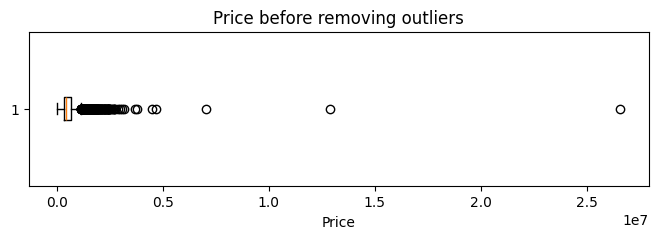

In [8]:
# Boxplot before removing outliers
plt.figure(figsize=(8, 2))
plt.boxplot(df['price'], vert=False)
plt.title('Price before removing outliers')
plt.xlabel('Price')
plt.show()

In [9]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 3 * IQR
upper = Q3 + 3 * IQR
rows_before = len(df)
df = df[(df['price'] >= lower) & (df['price'] <= upper)].copy()
print(f'Price bounds used: {lower:,.2f} to {upper:,.2f}')
print(f'Removed extreme-price rows: {rows_before - len(df)}')
print(f'Rows remaining: {len(df)}')

Price bounds used: -668,100.00 to 1,651,700.00
Removed extreme-price rows: 89
Rows remaining: 4460


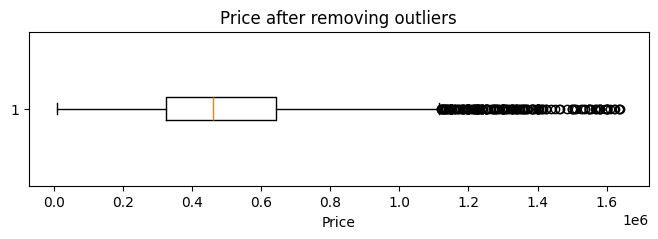

In [10]:
# Boxplot after removing outliers
plt.figure(figsize=(8, 2))
plt.boxplot(df['price'], vert=False)
plt.title('Price after removing outliers')
plt.xlabel('Price')
plt.show()

STEP 4: EXPLORE THE DATA (EDA)

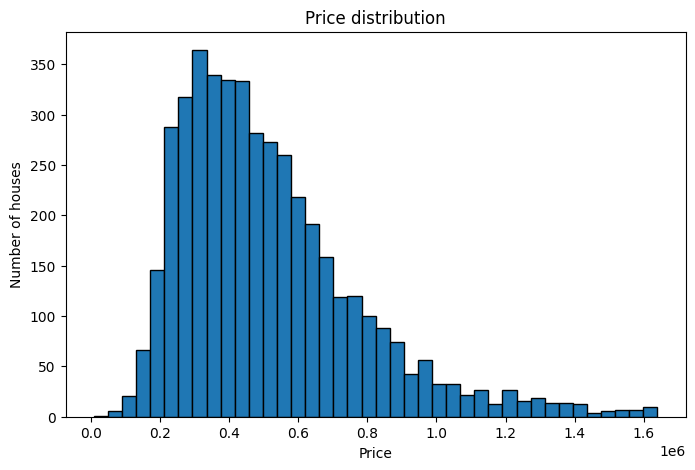

In [11]:
# Price distribution
plt.figure(figsize=(8, 5))
plt.hist(df['price'], bins=40, edgecolor='black')
plt.title('Price distribution')
plt.xlabel('Price')
plt.ylabel('Number of houses')
plt.show()

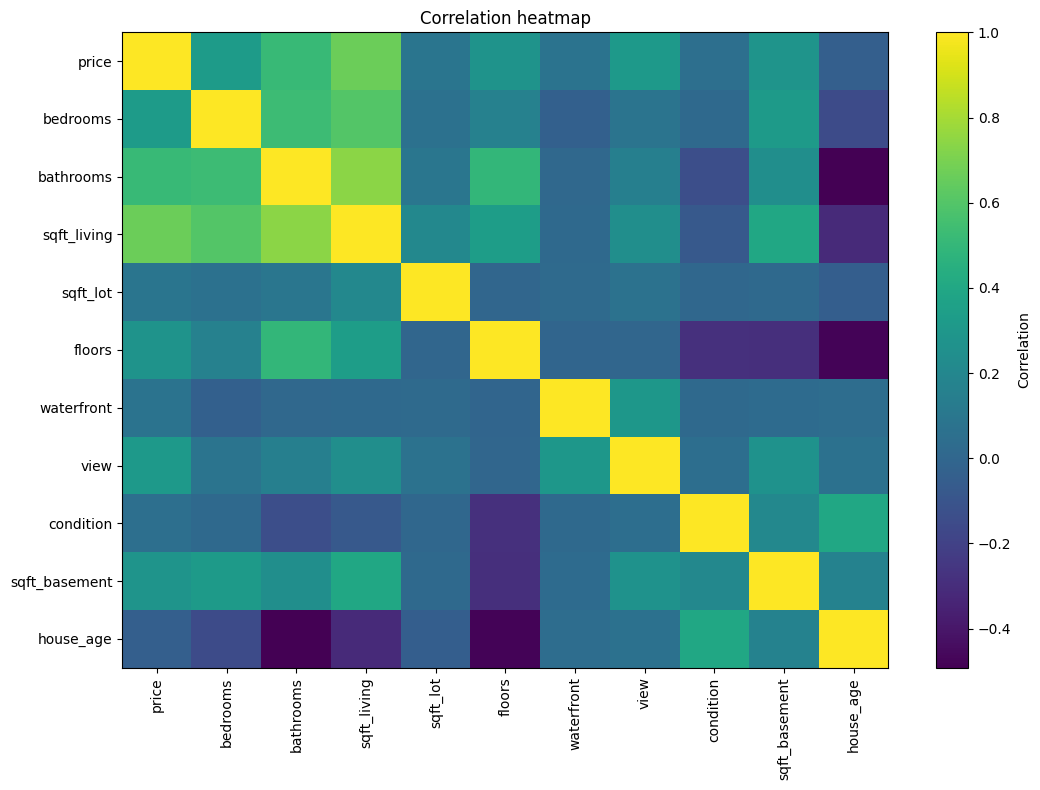

In [12]:
# Correlation heatmap for numeric columns
corr = df.corr(numeric_only=True)
plt.figure(figsize=(11, 8))
image = plt.imshow(corr, aspect='auto', interpolation='nearest')
plt.colorbar(image, label='Correlation')
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title('Correlation heatmap')
plt.tight_layout()
plt.show()

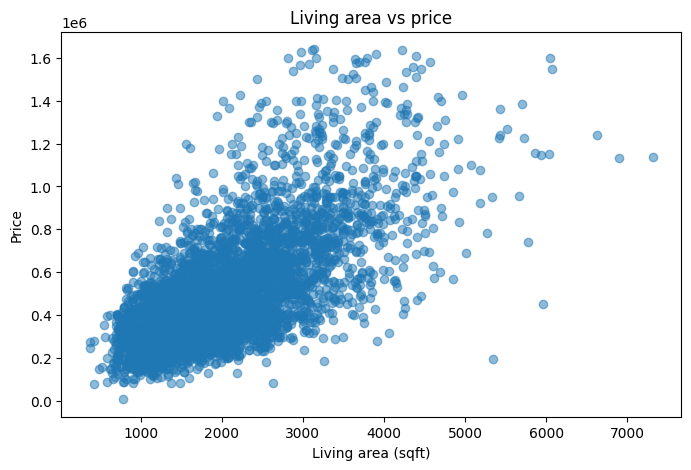

In [13]:
# Living area vs price
plt.figure(figsize=(8, 5))
plt.scatter(df['sqft_living'], df['price'], alpha=0.5)
plt.title('Living area vs price')
plt.xlabel('Living area (sqft)')
plt.ylabel('Price')
plt.show()

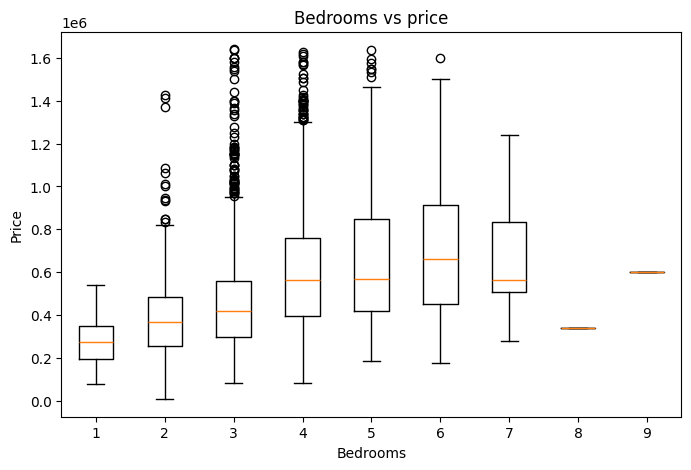

In [14]:
# Price distribution by bedroom count
bedroom_groups = sorted(df['bedrooms'].unique())
price_groups = [df.loc[df['bedrooms'] == bedroom, 'price'] for bedroom in bedroom_groups]
plt.figure(figsize=(8, 5))
plt.boxplot(price_groups, tick_labels=bedroom_groups)
plt.title('Bedrooms vs price')
plt.xlabel('Bedrooms')
plt.ylabel('Price')
plt.show()

**Initial EDA observations**

- The scatter plot helps inspect the relationship between living area (`sqft_living`) and price.
- The box plot compares price distributions across bedroom counts.
- The correlation heatmap shows pairwise linear correlations among numeric columns.
- These plots are useful for identifying patterns, but they do not by themselves prove which feature is most important or that location improves model performance. Those claims would require additional model-based analysis.

## STEP 5: PREPARE DATA FOR THE MODEL

Keep `statezip` as a categorical feature for now. Split the raw features into training and test sets **before fitting preprocessing**, so the encoder and scaler learn only from the training data.

In [15]:
# X contains input features; y is the target we want to predict
X = df.drop(columns=['price'])
y = df['price']

print('Input feature shape before encoding:', X.shape)
print('Target shape:', y.shape)
print('Categorical columns:', X.select_dtypes(include=['object', 'category']).columns.tolist())

Input feature shape before encoding: (4460, 11)
Target shape: (4460,)
Categorical columns: ['statezip']


In [16]:
# Split into training and test sets (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print('Train:', X_train.shape)
print('Test :', X_test.shape)

Train: (3568, 11)
Test : (892, 11)


In [17]:
# Fit preprocessing on training data only.
# Numeric features are standardized; statezip is one-hot encoded.
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

categorical_features = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', StandardScaler(), numeric_features),
        ('categorical', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features)
    ]
)

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

print('Numeric features:', len(numeric_features))
print('Categorical features:', categorical_features)

Numeric features: 10
Categorical features: ['statezip']


STEP 6: TRAIN THE LINEAR REGRESSION MODEL

In [18]:
# Train the complete preprocessing + regression pipeline
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print('Model training complete.')

Model training complete.


STEP 7: EVALUATE THE MODEL (MSE and R²)

In [19]:
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f'MSE:  {mse:,.2f}')
print(f'RMSE: {rmse:,.2f}')
print(f'R²:   {r2:.3f}')

MSE:  15,378,916,831.64
RMSE: 124,011.76
R²:   0.782


STEP 8: ACTUAL vs PREDICTED PRICES

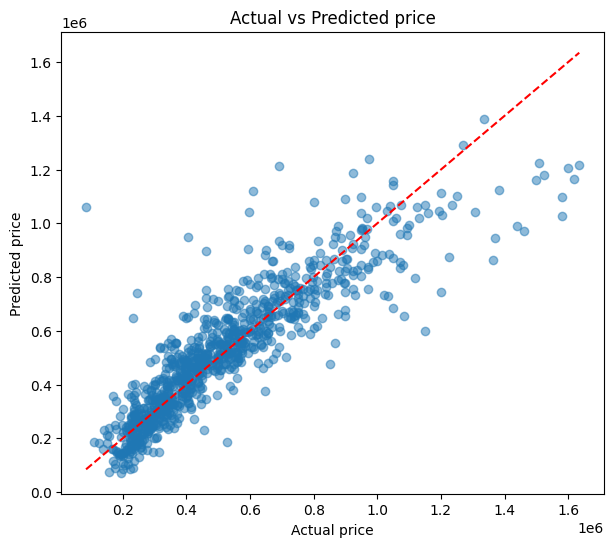

In [20]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Actual price')
plt.ylabel('Predicted price')
plt.title('Actual vs Predicted price')
plt.show()

## Conclusion

- Inspected the dataset, checked missing values and duplicates, and documented data-cleaning decisions.
- Excluded zero-price records and two records with both bedroom and bathroom counts equal to zero.
- Used a 3 × IQR rule to remove the most extreme price values for this baseline; some excluded properties may be legitimate high-value homes.
- Engineered `house_age` and used numeric features plus one-hot-encoded `statezip` as model inputs.
- Split the data into training and test sets before fitting the preprocessing pipeline to avoid learning category/scaling information from the test set.
- Trained a Linear Regression model and evaluated it with MSE, RMSE, and R². The test-set R² is reported in the evaluation cell above; it describes this test split, not guaranteed performance on new markets or datasets.
- The actual-vs-predicted scatter plot compares predictions with the ideal diagonal line. Points closer to the line indicate closer predictions.

### Limitations and possible next steps

- The model is a baseline; Linear Regression may not capture nonlinear price relationships.
- Outlier treatment and feature selection affect the results.
- Next steps could include comparing against a DummyRegressor baseline, trying tree-based models, and evaluating errors across price ranges.